# Cours 3 — Patterns, associations et anomalies (7 jeux ERP)

**M2 Data Science · Data Mining · Travail de groupe · Domaine logistique**

Sept fichiers ERP sources : partenaires, installations, bons de réception, mouvements correctifs, inventaire mensuel, **lignes de commandes d’achat**, **expéditions**. Les calculs utilisent exclusivement les données ERP ; tous les signaux sont des *hypothèses à vérifier*, jamais des preuves de fraude.

## 1. Apriori, co-occurrences et règles d’association

Cours 3 : itemsets fréquents, support, confiance et lift. Trois ensembles de transactions séparés : commandes, réceptions, expéditions. Une règle statistique **ne démontre pas** une fraude ; un lift élevé peut résulter de champs structurellement dépendants.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd()
if not (ROOT/'data/raw').exists(): ROOT=ROOT.parent
assert (ROOT/'data/raw').exists(), "Ouvrir le notebook depuis la racine du dépôt ou son répertoire notebooks/"
SEED=42
pd.set_option('display.max_columns',35)
pd.set_option('display.max_colwidth',85)
from itertools import combinations
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
D=ROOT/'data/part1_clean';OUT=ROOT/'data/part3_patterns';OUT.mkdir(exist_ok=True,parents=True)
def ld(s):return pd.read_csv(D/f'{s}_clean.csv')
bp=ld('erp_business_partners');fc=ld('erp_facilities');po=ld('purchase_order_lines');gr=ld('goods_receipts');sh=ld('shipments');ad=ld('inventory_adjustments');mo=ld('inventory_month_end')


In [2]:
source_col={'purchase_order_lines':(po,['authorization_class','order_status','item_category','ordered_unit']),
            'goods_receipts':(gr,['inspection_status','receipt_status','received_unit']),
            'shipments':(sh,['authorization_class','shipment_status','temperature_control_class','declared_unit','item_category'])}
itemsets=[];rules=[]
for source,(frame,cols) in source_col.items():
 T=[frozenset(f'{c}={r[c]}' for c in cols if pd.notna(r[c])) for _,r in frame.iterrows()]
 previous={frozenset([x]) for t in T for x in t};freq={}
 for size in (1,2,3):
  current={x:sum(x.issubset(t) for t in T)/len(T) for x in previous}
  current={x:s for x,s in current.items() if s>=.06};freq.update(current)
  if not current or size==3:break
  universe=sorted(set().union(*current));previous={frozenset(c) for c in combinations(universe,size+1) if all(frozenset(q) in current for q in combinations(c,size))}
 for x,s in freq.items():
  itemsets.append({'source_dataset':source,'itemset':' | '.join(sorted(x)),'size':len(x),'support':s})
  if len(x)>1:
   for z in range(1,len(x)):
    for a in combinations(sorted(x),z):
     lhs=frozenset(a);rhs=x-lhs
     if lhs in freq and rhs in freq:
      conf=s/freq[lhs];lift=conf/freq[rhs]
      if conf>=.6 and lift>=1.15:rules.append({'source_dataset':source,'antecedent':' | '.join(sorted(lhs)),'consequent':' | '.join(sorted(rhs)),'support':s,'confidence':conf,'lift':lift,'leverage':s-freq[lhs]*freq[rhs]})
it=pd.DataFrame(itemsets).sort_values('support',ascending=False)
rr=pd.DataFrame(rules,columns=['source_dataset','antecedent','consequent','support','confidence','lift','leverage']).sort_values('lift',ascending=False)
it.to_csv(OUT/'frequent_itemsets.csv',index=False);rr.to_csv(OUT/'association_rules.csv',index=False)
print('Itemsets:',len(it),' / règles:',len(rr));display(rr.head(10).round(3))


Itemsets: 202  / règles: 154


,source_dataset,antecedent,consequent,support,confidence,lift,leverage
9,purchase_order_lines,ordered_unit=sealed_lot,item_category=biological_sample,0.065,1.000,15.476,0.060
8,purchase_order_lines,item_category=biological_sample,ordered_unit=sealed_lot,0.065,1.000,15.476,0.060
21,purchase_order_lines,ordered_unit=sealed_lot,item_category=biological_sample | order_status=completed,0.060,0.929,15.476,0.056
20,purchase_order_lines,item_category=biological_sample,order_status=completed | ordered_unit=sealed_lot,0.060,0.929,15.476,0.056
23,purchase_order_lines,order_status=completed | ordered_unit=sealed_lot,item_category=biological_sample,0.060,1.000,15.476,0.056
22,purchase_order_lines,item_category=biological_sample | order_status=completed,ordered_unit=sealed_lot,0.060,1.000,15.476,0.056
6,purchase_order_lines,item_category=laboratory_material,ordered_unit=pack,0.068,1.000,14.773,0.063
7,purchase_order_lines,ordered_unit=pack,item_category=laboratory_material,0.068,1.000,14.773,0.063
27,purchase_order_lines,ordered_unit=pack,item_category=laboratory_material | order_status=completed,0.063,0.932,14.773,0.059
26,purchase_order_lines,item_category=laboratory_material,order_status=completed | ordered_unit=pack,0.063,0.932,14.773,0.059


## 2. Commande → réception : jointure composite et contrôles de cohérence

Les deux fichiers supplémentaires rendent possible la vérification des **lignes de commandes**. La clé exacte est `(purchase_order_number, purchase_order_line)`. Une ligne PO peut recevoir plusieurs réceptions : comparer le cumul aux quantités commandées seulement quand l’unité est identique. Des dépassements peuvent provenir de tolérances contractuelles.

In [3]:
JOIN=['purchase_order_number','purchase_order_line']
matching=gr.merge(po,on=JOIN,how='left',suffixes=('_receipt','_po'),indicator=True,validate='many_to_one')
matching['found_po']=matching._merge.eq('both')
matching['flag_supplier_mismatch']=matching.found_po & ~matching.supplier_partner_code_receipt.eq(matching.supplier_partner_code_po)
matching['flag_facility_mismatch']=matching.found_po & ~matching.receiving_facility_code.eq(matching.ordering_facility_code)
matching['flag_unit_mismatch']=matching.found_po & ~matching.received_unit.eq(matching.ordered_unit)
matching['flag_precedes_order']=matching.found_po & (pd.to_datetime(matching.receipt_date,errors='coerce')<pd.to_datetime(matching.order_date,errors='coerce'))
matching.to_csv(OUT/'erp_receipts_vs_purchase_orders.csv',index=False)
agg=matching.loc[matching.found_po & ~matching.flag_unit_mismatch].groupby(JOIN).received_quantity.sum().reset_index(name='total_received')
fulfil=po.merge(agg,on=JOIN,how='left');fulfil['total_received']=fulfil.total_received.fillna(0)
fulfil['ratio']=np.where(fulfil.ordered_quantity>0,fulfil.total_received/fulfil.ordered_quantity,np.nan)
fulfil['flag_over_received']=fulfil.ratio>1.10;fulfil.to_csv(OUT/'erp_purchase_order_fulfillment.csv',index=False)
print('Réceptions sans PO :',int((~matching.found_po).sum()),' / fournisseur différent :',int(matching.flag_supplier_mismatch.sum()),' / unité différente :',int(matching.flag_unit_mismatch.sum()))
print('Lignes PO > 110 % (unité concordante) :',int(fulfil.flag_over_received.sum()))


Réceptions sans PO : 0  / fournisseur différent : 0  / unité différente : 0
Lignes PO > 110 % (unité concordante) : 0


## 3. Expéditions : chronologie, routes, statut et lien vers ajustements

On peut **vérifier** `related_shipment_number` par égalité exacte avec `shipment_number`. Cependant le fichier des réceptions n'a aucun identifiant d'expédition : on ne doit pas inventer une correspondance réception/expédition. Des expéditions `restricted`, `delayed` ou `returned` ne sont pas automatiquement frauduleuses.

In [4]:
ship=sh.copy();ship['dispatch_dt']=pd.to_datetime(ship.dispatch_time);ship['arrival_dt']=pd.to_datetime(ship.arrival_time)
ship['transit_hours']=(ship.arrival_dt-ship.dispatch_dt).dt.total_seconds()/3600
ship['flag_negative_duration']=ship.transit_hours.lt(0)
ship['flag_delivered_without_arrival']=ship.shipment_status.eq('delivered')&ship.arrival_dt.isna()
ship.to_csv(OUT/'erp_shipments_screened.csv',index=False)
ref=ad.loc[ad.related_shipment_number.notna()].merge(sh[['shipment_number','shipment_leg','origin_facility_code','destination_facility_code','item_category','declared_unit','dispatch_time','arrival_time']],left_on='related_shipment_number',right_on='shipment_number',how='left',suffixes=('_adjustment','_shipment'),indicator=True)
ref['found_shipment']=ref._merge.eq('both')
ref['flag_outside_route']=ref.found_shipment & ~(ref.facility_code.eq(ref.origin_facility_code)|ref.facility_code.eq(ref.destination_facility_code))
ref['flag_unit_mismatch']=ref.found_shipment & ~ref.unit.eq(ref.declared_unit)
ref['flag_category_mismatch']=ref.found_shipment & ~ref.item_category_adjustment.eq(ref.item_category_shipment)
ref.to_csv(OUT/'erp_adjustment_shipment_links.csv',index=False)
print('Durées négatives:',int(ship.flag_negative_duration.sum()),' / ajustements sans shipment trouvé:',int((~ref.found_shipment).sum()),' / ajustements hors route:',int(ref.flag_outside_route.sum()))


Durées négatives: 0  / ajustements sans shipment trouvé: 0  / ajustements hors route: 18


## 4. Stock, valeurs extrêmes et modèles non supervisés

Réconciliation mensuelle par **site + catégorie + unité + mois** ; la formule simplifiée de clôture ignore de possibles mouvements non observés. IQR sur les valeurs absolues **au sein d’une même unité**. LOF et Isolation Forest détectent des profils rares mais ne produisent pas une probabilité de fraude.

Écarts stocks >5 unités : 47  / corrections antérieures à la réception : 11


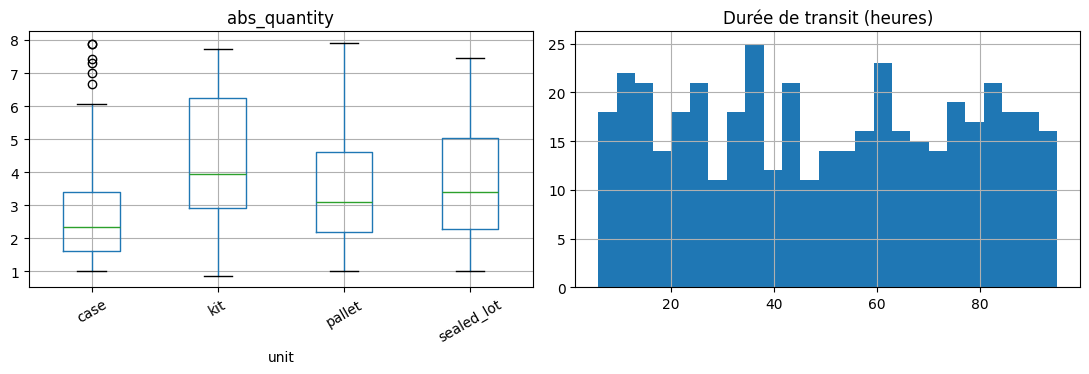

In [5]:
rcl=gr[['receipt_number','receipt_date','receiving_facility_code']]
link=ad.loc[ad.related_receipt_number.notna()].merge(rcl,left_on='related_receipt_number',right_on='receipt_number',how='left',indicator=True)
link['found_receipt']=link._merge.eq('both')
link['flag_precedes_receipt']=link.found_receipt & (pd.to_datetime(link.adjustment_date)<pd.to_datetime(link.receipt_date))
link['flag_other_facility']=link.found_receipt & ~link.facility_code.eq(link.receiving_facility_code)
link.to_csv(OUT/'erp_adjustment_receipt_links.csv',index=False)
rec=mo.copy();rec['expected_closing_stock']=rec.opening_stock+rec.received_quantity-rec.outgoing_quantity-rec.documented_internal_use-rec.documented_waste
rec['stock_variance']=rec.closing_stock-rec.expected_closing_stock;rec['flag_variance_gt5']=rec.stock_variance.abs()>5
rec.to_csv(OUT/'inventory_reconciliation.csv',index=False)
Q=ad.copy();Q['abs_quantity']=Q.adjustment_quantity.abs();Q['flag_iqr']=False
for unit,ids in Q.groupby('unit').groups.items():
 v=Q.loc[ids,'abs_quantity'].dropna()
 if len(v)<6:continue
 q1,q3=v.quantile([.25,.75]);Q.loc[ids,'flag_iqr']=Q.loc[ids,'abs_quantity']>q3+1.5*(q3-q1)
Q.to_csv(OUT/'inventory_adjustments_scored.csv',index=False)
pf=pd.read_csv(ROOT/'data/part2_cluster/erp_partner_profiles_clustered.csv');features=[c for c in pf if c.startswith('n_')]
X=StandardScaler().fit_transform(np.log1p(pf[features].fillna(0)))
lof=LocalOutlierFactor(n_neighbors=15,contamination=.1);pf['lof_flag']=lof.fit_predict(X)==-1;pf['lof_score']=-lof.negative_outlier_factor_
iso=IsolationForest(n_estimators=200,contamination=.1,random_state=SEED);pf['iforest_flag']=iso.fit_predict(X)==-1;pf['iforest_score']=-iso.score_samples(X)
pf.to_csv(OUT/'erp_partner_anomaly_scores.csv',index=False)
print('Écarts stocks >5 unités :',int(rec.flag_variance_gt5.sum()),' / corrections antérieures à la réception :',int(link.flag_precedes_receipt.sum()))
fig,ax=plt.subplots(1,2,figsize=(11,4))
Q.boxplot(column='abs_quantity',by='unit',ax=ax[0]);ax[0].tick_params(axis='x',rotation=30)
ship.loc[ship.transit_hours.ge(0),'transit_hours'].hist(bins=25,ax=ax[1]);ax[1].set_title('Durée de transit (heures)')
plt.suptitle('');plt.tight_layout();(ROOT/'figures').mkdir(exist_ok=True);plt.savefig(ROOT/'figures/cours3_anomalies_7.png',dpi=130);plt.show()


## 5. Journal des alertes : identifiant, règle, gravité de revue, justification

Les signaux issus de **PO, expéditions et rapprochements de stocks** sont conservés séparément avec les identifiants sources. Plusieurs alertes peuvent viser la même ligne. Une classe de priorité n’est **ni une accusation ni une probabilité**.

In [6]:
findings=[]
def flag(dataset,id,facility,partner,date,category,unit,rule,priority,related='',value=np.nan,reason=''):
 findings.append({'source_domain':'ERP','source_dataset':dataset,'record_id':str(id),'facility_code':facility,'partner_code':partner,'event_date':date,'item_category':category,'unit':unit,'rule_id':rule,'review_priority':priority,'related_record_id':related,'numeric_value':value,'explanation_fr':reason,'claim_status':'review_only_not_proof'})
for r in matching.itertuples(index=False):
 context=('goods_receipts',r.receipt_number,r.receiving_facility_code,r.supplier_partner_code_receipt,r.receipt_date,r.item_category,r.received_unit)
 if not r.found_po:flag(*context,'receipt_without_po','high',r.purchase_order_number,reason='Réception sans ligne de commande exacte.');continue
 for condition,rule,reason in [(r.flag_supplier_mismatch,'receipt_supplier_mismatch','Fournisseur commandé et reçu différents.'),(r.flag_facility_mismatch,'receipt_facility_mismatch','Sites de commande/réception différents.'),(r.flag_unit_mismatch,'receipt_unit_mismatch','Unités de commande/réception différentes.'),(r.flag_precedes_order,'receipt_before_order','Réception antérieure à la commande.')]:
  if condition:flag(*context,rule,'high' if rule in ('receipt_supplier_mismatch','receipt_before_order') else 'review',r.purchase_order_number,reason=reason)
for r in fulfil.loc[fulfil.flag_over_received].itertuples(index=False):
 flag('purchase_order_lines',f'{r.purchase_order_number}:{int(r.purchase_order_line)}',r.ordering_facility_code,r.supplier_partner_code,r.order_date,r.item_category,r.ordered_unit,'po_over_received_110pct','review',r.purchase_order_number,r.ratio,'Volume total reçu >110 % de la quantité commandée (unité identique).')
for r in ship.itertuples(index=False):
 context=('shipments',f'{r.shipment_number}:{int(r.shipment_leg)}',r.destination_facility_code,r.receiver_partner_code,r.dispatch_time[:10] if isinstance(r.dispatch_time,str) else np.nan,r.item_category,r.declared_unit)
 if r.flag_negative_duration:flag(*context,'negative_transit_time','high',r.shipment_number,r.transit_hours,'Arrivée datée avant le départ.')
 if r.flag_delivered_without_arrival:flag(*context,'delivered_without_arrival','review',r.shipment_number,reason='Livrée sans date d’arrivée.')
for r in link.itertuples(index=False):
 context=('inventory_adjustments',r.adjustment_number,r.facility_code,np.nan,r.adjustment_date,r.item_category,r.unit)
 if not r.found_receipt:flag(*context,'adjustment_unknown_receipt','high',r.related_receipt_number,reason='Réception référencée introuvable.')
 if r.flag_precedes_receipt:flag(*context,'adjustment_before_receipt','high',r.related_receipt_number,reason='Correction antérieure à la réception.')
 if r.flag_other_facility:flag(*context,'adjustment_other_receipt_facility','review',r.related_receipt_number,reason='Correction à un site différent de la réception.')
for r in ref.itertuples(index=False):
 context=('inventory_adjustments',r.adjustment_number,r.facility_code,np.nan,r.adjustment_date,r.item_category_adjustment,r.unit)
 if not r.found_shipment:flag(*context,'adjustment_unknown_shipment','high',r.related_shipment_number,reason='Expédition référencée introuvable.')
 for value,rule,why in [(r.flag_outside_route,'adjustment_not_at_shipment_endpoints','Correction hors des sites d’origine/destination.'),(r.flag_unit_mismatch,'adjustment_shipment_unit_mismatch','Unités différentes entre correction et expédition.'),(r.flag_category_mismatch,'adjustment_shipment_category_mismatch','Catégories différentes entre correction et expédition.')]:
  if value:flag(*context,rule,'review',r.related_shipment_number,reason=why)
for r in rec.loc[rec.flag_variance_gt5].itertuples(index=False):
 flag('inventory_month_end',f'{r.facility_code}:{r.reporting_month}:{r.item_category}:{r.unit}',r.facility_code,np.nan,r.reporting_month,r.item_category,r.unit,'stock_variance_gt5','review',value=r.stock_variance,reason='Écart de clôture dans la même unité ; formule simplifiée.')
for r in Q.loc[Q.flag_iqr].itertuples(index=False):
 flag('inventory_adjustments',r.adjustment_number,r.facility_code,np.nan,r.adjustment_date,r.item_category,r.unit,'adjustment_quantity_iqr','statistical',value=r.adjustment_quantity,reason='Quantité rare par rapport aux ajustements de même unité.')
for r in pf.loc[pf.lof_flag & pf.iforest_flag].itertuples(index=False):
 flag('erp_business_partners',r.partner_code,np.nan,r.partner_code,np.nan,np.nan,np.nan,'rare_activity_profile','statistical',value=r.iforest_score,reason='Profil rare selon LOF et Isolation Forest.')
cols=['source_domain','source_dataset','record_id','facility_code','partner_code','event_date','item_category','unit','rule_id','review_priority','related_record_id','numeric_value','explanation_fr','claim_status']
find=pd.DataFrame(findings,columns=cols);find.to_csv(OUT/'erp_review_findings.csv',index=False)
print('Alertes:',len(find),' / enregistrements uniques:',len(find[['source_dataset','record_id']].drop_duplicates()))
display(find.rule_id.value_counts().rename_axis('rule_id').reset_index(name='n'))


Alertes: 140  / enregistrements uniques: 88


,rule_id,n
0,stock_variance_gt5,47
1,adjustment_other_receipt_facility,21
2,adjustment_not_at_shipment_endpoints,18
3,adjustment_shipment_unit_mismatch,17
4,adjustment_shipment_category_mismatch,17
5,adjustment_before_receipt,11
6,adjustment_quantity_iqr,6
7,rare_activity_profile,3


## 6. Export `site × mois × unité` et index des expéditions

Destiné aux autres groupes. Les champs de site sont **des identifiants ERP** ; les sites des autres domaines doivent d’abord être rapprochés de façon contrôlée. Compter les événements séparément par catégorie et unité ; **ne pas** additionner `case` et `sealed_lot`.

In [7]:
tables=[]
for activity,t,sitecol,datecol,unitcol,catcol in [
 ('order',po,'ordering_facility_code','order_date','ordered_unit','item_category'),
 ('receipt',gr,'receiving_facility_code','receipt_date','received_unit',None),
 ('shipment_departure',sh,'origin_facility_code','dispatch_time','declared_unit','item_category'),
 ('shipment_arrival',sh,'destination_facility_code','arrival_time','declared_unit','item_category'),
 ('adjustment',ad,'facility_code','adjustment_date','unit','item_category')]:
 a=pd.DataFrame({'facility_code':t[sitecol],'month':pd.to_datetime(t[datecol],errors='coerce').dt.strftime('%Y-%m'),'unit':t[unitcol],'item_category':t[catcol] if catcol else 'not_recorded','activity':activity})
 tables.append(a.groupby(['facility_code','month','unit','item_category','activity'],dropna=False).size().reset_index(name='n_events'))
activity=pd.concat(tables,ignore_index=True);activity.to_csv(OUT/'erp_facility_month_activity.csv',index=False)
shipref=ref[['adjustment_number','related_shipment_number','facility_code','adjustment_date','shipment_number','shipment_leg','origin_facility_code','destination_facility_code','dispatch_time','arrival_time','found_shipment','flag_outside_route','flag_unit_mismatch','flag_category_mismatch']]
shipref.to_csv(OUT/'erp_shipment_reference_index.csv',index=False)
display(Markdown(f'**Interprétation du cours 3** — {len(find)} alertes à examiner, dont certaines portent sur les mêmes enregistrements ; {len(sh)} expéditions, {len(po)} lignes PO. Les liens *ajustement → expédition* sont vérifiés par identifiant, mais il manque une clé explicite *réception → expédition*.'))


**Interprétation du cours 3** — 140 alertes à examiner, dont certaines portent sur les mêmes enregistrements ; 450 expéditions, 650 lignes PO. Les liens *ajustement → expédition* sont vérifiés par identifiant, mais il manque une clé explicite *réception → expédition*.